In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

In [2]:
PROJECT_ROOT = Path("../")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.datasets.dsad_dataset import DSADDataset


In [4]:
global_config_path = PROJECT_ROOT / "configs" / "config.yaml"
dataset_config_path = PROJECT_ROOT / "configs" / "experiment" / "baseline" / "dsad.yaml"


global_cfg = OmegaConf.load(global_config_path)
dataset_cfg = OmegaConf.load(dataset_config_path)

cfg = OmegaConf.merge(global_cfg, dataset_cfg)

print(OmegaConf.to_yaml(cfg))

defaults:
- experiment: baseline/cholec_instance_seg8k
- model: baseline/unet
- _self_
experiment:
  seed: 42
  debug: false
paths:
  data: /work/tesi_cmininno/dataset
  output: ${hydra:runtime.cwd}/experiments
  checkpoint: /work/tesi_cmininno/checkpoint/${name}/${model.name}
device: cuda
logging:
  wandb:
    enabled: true
    project: surgical_scene_segmentation
    entity: mininnoclaudio-unimore
    mode: online
  experiment_name: dsad_baseline
  tags:
  - dsad
  - single_organ
  - baseline
name: dsad_baseline
data:
  name: dsad
  dataset:
    _target_: src.datasets.dsad_dataset.DSADDataset
    root: ${paths.data}/DSAD
  variant: single_organ
  split:
    type: official
    train: train
    validation: validation
    test: test
  num_classes: 2
  classes:
    0: background
    1: organ
preprocessing:
  image:
    size:
    - 512
    - 640
    channel_first: true
    dtype: float32
    normalize: true
  mask:
    channel_first: true
    dtype: long
augmentation:
  train:
    enabled

In [ ]:
dataset = DSADDataset(root=cfg.data.dataset.root)


In [5]:
train_dataset, val_dataset, test_dataset = dataset.create_official_split()

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 7889
Validation: 1978
Test: 3328


In [6]:
sample = dataset[0]

print(sample["image"].shape)
print(sample["image"].dtype)

print(sample["mask"].shape)
print(sample["mask"].dtype)
print(np.unique(sample["mask"]))

print(sample["organ"])
print(sample["surgery_id"])
print(sample["frame_id"])

(1024, 1280, 3)
uint8
(1024, 1280)
uint8
[0 1]
abdominal_wall
04
0


In [7]:
def plot_original_sample(sample, figsize=(15, 5)):

    image = sample["image"]
    mask = sample["mask"]

    fig, axes = plt.subplots(1, 3, figsize=figsize)

    # Original image
    axes[0].imshow(image)
    axes[0].set_title(
        f"Original Image\n"
        f"organ={sample['organ']}\n"
        f"surgery={sample['surgery_id']}, "
        f"frame={sample['frame_id']}"
    )
    axes[0].axis("off")

    # Original mask
    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title(
        f"Original Mask\n"
        f"unique={np.unique(mask)}"
    )
    axes[1].axis("off")

    # Original overlay
    axes[2].imshow(image)
    axes[2].imshow(
        mask,
        alpha=0.4,
        cmap="jet"
    )
    axes[2].set_title("Original Overlay")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

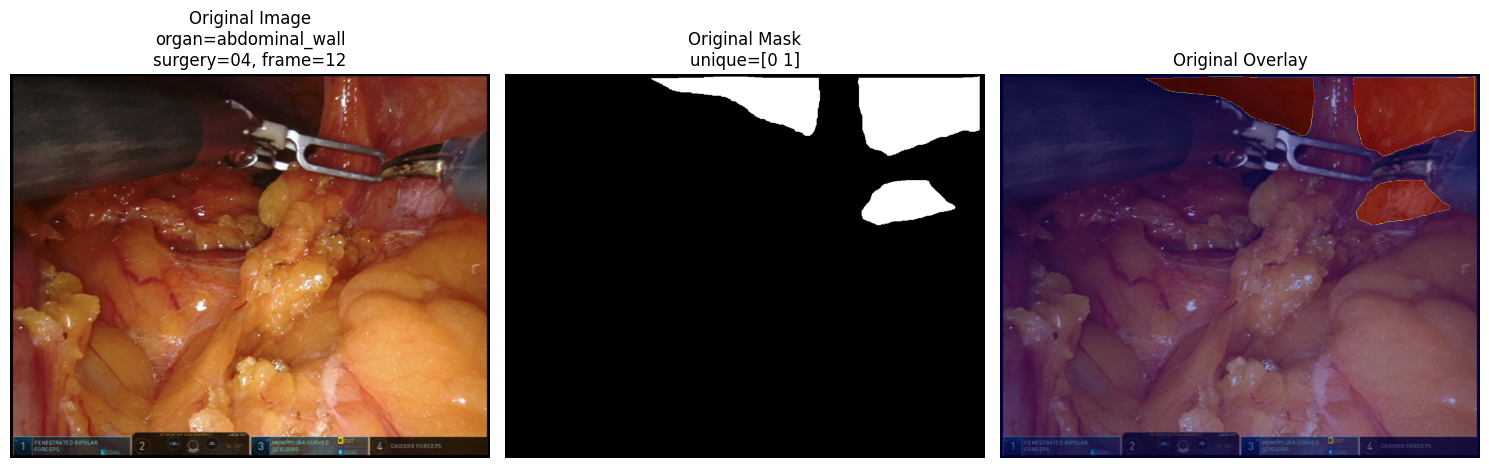

In [9]:
plot_original_sample(train_dataset[12])

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from torch.utils.data import DataLoader

from src.datasets.transformation.transform_dataset import TransformDataset
from src.datasets.transformation.factory import TransformFactory


In [16]:
factory = TransformFactory(cfg)


In [17]:
train_dataset = TransformDataset(
    train_dataset,
    factory.build_train_transform()
)

val_dataset = TransformDataset(
    val_dataset,
    factory.build_val_transform()
)

test_dataset = TransformDataset(
    test_dataset,
    factory.build_test_transform()
)

In [18]:
train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.train.batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=cfg.train.pin_memory,
)

In [19]:
batch = next(iter(train_loader))

print("Batch keys:")
print(batch.keys())

print("\nShapes:")

for key, value in batch.items():
    if hasattr(value, "shape"):
        print(f"{key}: {value.shape}")

RuntimeError: applying transform <monai.transforms.spatial.dictionary.RandFlipd object at 0x7f29d11ded10>

In [ ]:
def to_numpy_image(image):
    """
    Convert image tensor/array to HWC numpy format.
    """
    if torch.is_tensor(image):
        image = image.detach().cpu().numpy()

    if image.ndim == 3 and image.shape[0] in (1, 3):
        image = np.transpose(image, (1, 2, 0))

    return image


def to_numpy_mask(mask):
    """
    Convert mask tensor/array to HW numpy format.
    """
    if torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    mask = np.squeeze(mask)

    return mask

In [ ]:
def plot_sample(sample, figsize=(15, 5)):

    image = to_numpy_image(sample["image"])
    mask = to_numpy_mask(sample["mask"])

    fig, axes = plt.subplots(1, 3, figsize=figsize)

    # ---------------------------------------------------------
    # Image
    # ---------------------------------------------------------
    axes[0].imshow(image)
    axes[0].set_title(
        f"Image\n"
        f"organ={sample['organ']}\n"
        f"surgery={sample['surgery_id']}, "
        f"frame={sample['frame_id']}"
    )
    axes[0].axis("off")

    # ---------------------------------------------------------
    # Mask
    # ---------------------------------------------------------
    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title(
        f"Mask\n"
        f"unique={np.unique(mask)}"
    )
    axes[1].axis("off")

    # ---------------------------------------------------------
    # Overlay
    # ---------------------------------------------------------
    axes[2].imshow(image)
    axes[2].imshow(
        mask,
        alpha=0.4,
        cmap="jet"
    )
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
def get_sample_from_batch(batch, index=0):
    sample = {}

    for key, value in batch.items():

        if torch.is_tensor(value):
            sample[key] = value[index]

        elif isinstance(value, (list, tuple)):
            sample[key] = value[index]

        else:
            # Caso di metadata non collazionati nel modo previsto
            sample[key] = value

    return sample

In [ ]:
batch = next(iter(test_loader))

sample = get_sample_from_batch(batch, index=1)

print(sample.keys())
print("Organ:", sample["organ"])
print("Surgery:", sample["surgery_id"])
print("Frame:", sample["frame_id"])

plot_sample(sample)

In [ ]:
def plot_batch(batch, n=4, figsize=(15, 4)):

    n = min(n, len(batch["image"]))

    fig, axes = plt.subplots(
        n,
        3,
        figsize=(15, 4 * n)
    )

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):

        image = to_numpy_image(batch["image"][i])
        mask = to_numpy_mask(batch["mask"][i])

        # Image
        axes[i, 0].imshow(image)
        axes[i, 0].set_title(
            f"Image | "
            f"organ={batch['organ'][i]}\n"
            f"surgery={batch['surgery_id'][i]} "
            f"frame={batch['frame_id'][i]}"
        )
        axes[i, 0].axis("off")

        # Mask
        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title(
            f"Mask | unique={np.unique(mask)}"
        )
        axes[i, 1].axis("off")

        # Overlay
        axes[i, 2].imshow(image)
        axes[i, 2].imshow(
            mask,
            alpha=0.4,
            cmap="jet"
        )
        axes[i, 2].set_title("Overlay")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
batch = next(iter(test_loader))

plot_batch(batch, n=4)

In [ ]:
mask = batch["mask"]

print("Mask dtype:", mask.dtype)
print("Mask shape:", mask.shape)
print("Unique values:", torch.unique(mask))

In [ ]:
for i in range(len(batch["mask"])):

    mask = to_numpy_mask(batch["mask"][i])

    foreground_ratio = np.mean(mask > 0)

    print(
        f"Sample {i}: "
        f"organ={batch['organ'][i]}, "
        f"foreground={foreground_ratio * 100:.2f}%"
    )